In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 4.10.0
NumPy version: 1.26.4


Grayscale image loaded successfully


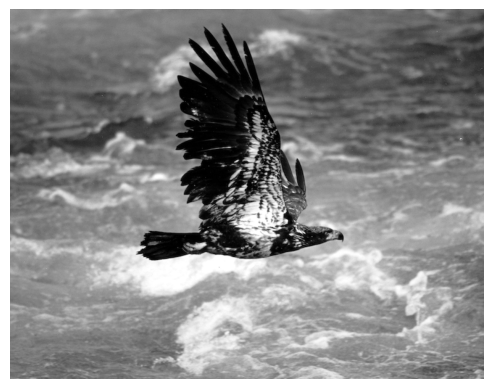

In [4]:
eagle_gray = cv2.imread("eagle.jpeg", cv2.IMREAD_GRAYSCALE)
if eagle_gray is not None:
    print("Grayscale image loaded successfully")
    plt.imshow(eagle_gray, cmap="gray")
    plt.axis("off")
    plt.show()
else:
    print("Image not found")

In [5]:
height, width = eagle_gray.shape
channels = 1
print(f"Width: {width} pixels\nHeight: {height} pixels\nChannels: {channels}")

Width: 768 pixels
Height: 600 pixels
Channels: 1


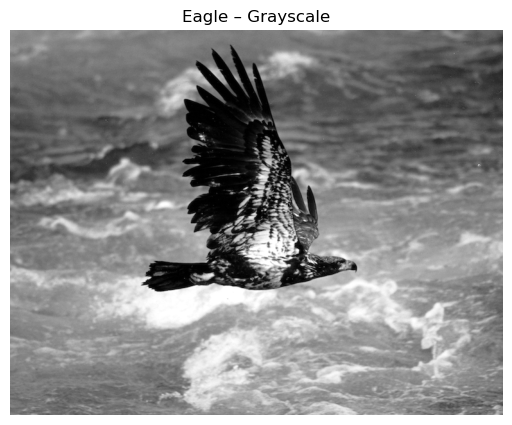

In [6]:
plt.figure(figsize=(9, 5))
plt.imshow(eagle_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Eagle – Grayscale")
plt.axis("off")
plt.show()

In [7]:
saved = cv2.imwrite("eagle_grayscale.png", eagle_gray)
print("Saved eagle_grayscale.png:", saved)

Saved eagle_grayscale.png: True


In [10]:
eagle_bgr = cv2.imread("eagle.jpeg", cv2.IMREAD_COLOR)
assert eagle_bgr is not None, "Eagle image not found"

eagle_from_png_rgb = cv2.cvtColor(eagle_bgr, cv2.COLOR_BGR2RGB)
print("Color image shape:", eagle_from_png_rgb.shape)

eagle_original_bgr = cv2.imread("eagle.jpeg", cv2.IMREAD_COLOR)
assert eagle_original_bgr is not None, "Original eagle image not found"

eagle_rgb = cv2.cvtColor(eagle_original_bgr, cv2.COLOR_BGR2RGB)

Color image shape: (600, 768, 3)


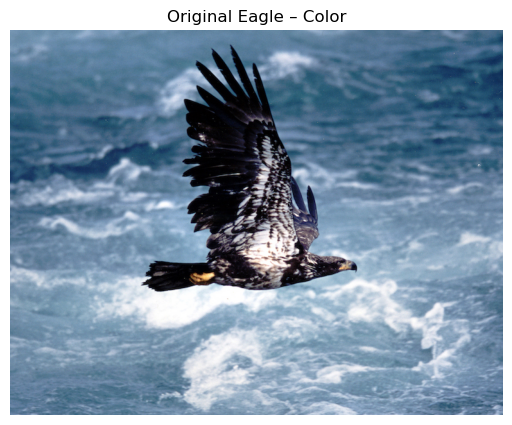

Width: 768, Height: 600, Channels: 3


In [11]:
plt.figure(figsize=(9, 5))
plt.imshow(eagle_rgb)
plt.title("Original Eagle – Color")
plt.axis("off")
plt.show()
h, w, c = eagle_rgb.shape
print(f"Width: {w}, Height: {h}, Channels: {c}")

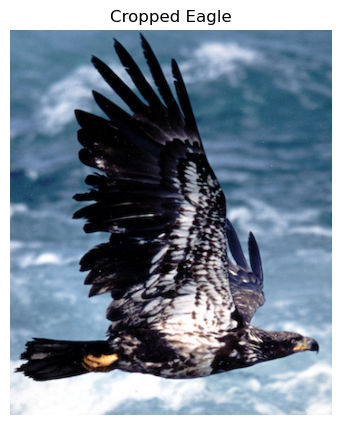

Cropped shape: (425, 355, 3)


In [12]:
# Crop coordinates: rows 20:445 and columns 200:555.
# Change these values if you want a tighter crop.
eagle_crop = eagle_rgb[20:445, 200:555]
plt.figure(figsize=(7, 5))
plt.imshow(eagle_crop)
plt.title("Cropped Eagle")
plt.axis("off")
plt.show()
print("Cropped shape:", eagle_crop.shape)

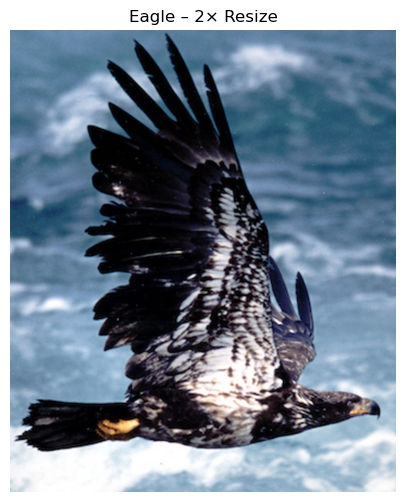

Original crop: (425, 355, 3) Resized: (850, 710, 3)


In [13]:
eagle_resized = cv2.resize(eagle_crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
plt.figure(figsize=(7, 6))
plt.imshow(eagle_resized)
plt.title("Eagle – 2× Resize")
plt.axis("off")
plt.show()
print("Original crop:", eagle_crop.shape, "Resized:", eagle_resized.shape)

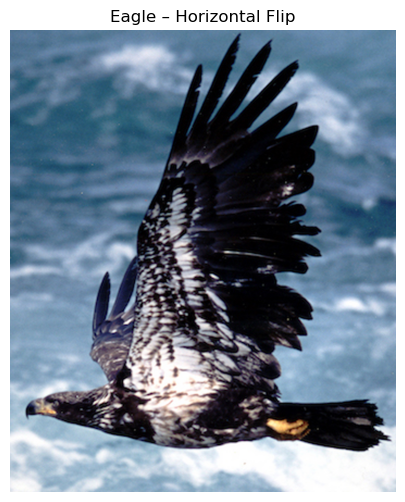

In [14]:
eagle_flipped = cv2.flip(eagle_resized, 1)
plt.figure(figsize=(7, 6))
plt.imshow(eagle_flipped)
plt.title("Eagle – Horizontal Flip")
plt.axis("off")
plt.show()

Apollo image shape: (720, 1280, 3)


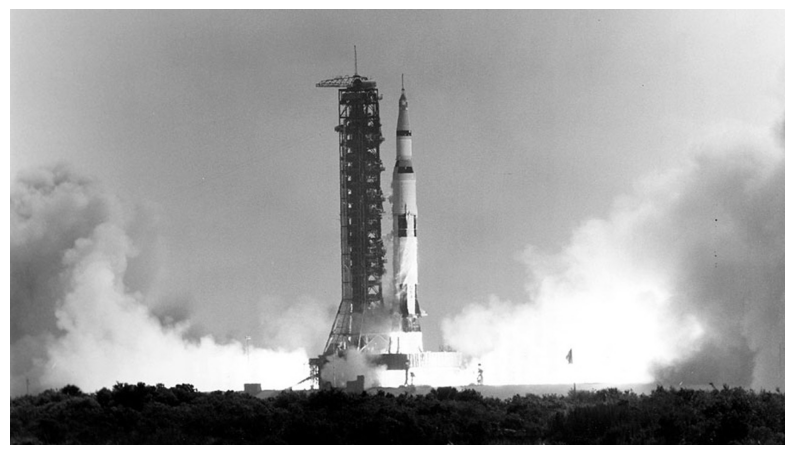

In [18]:
apollo_bgr = cv2.imread("Apollo-11-launch.jpeg", cv2.IMREAD_COLOR)
assert apollo_bgr is not None, "Apollo image not found"
apollo_rgb = cv2.cvtColor(apollo_bgr, cv2.COLOR_BGR2RGB)
print("Apollo image shape:", apollo_rgb.shape)
plt.figure(figsize=(10, 6))
plt.imshow(apollo_rgb)
plt.axis("off")
plt.show()

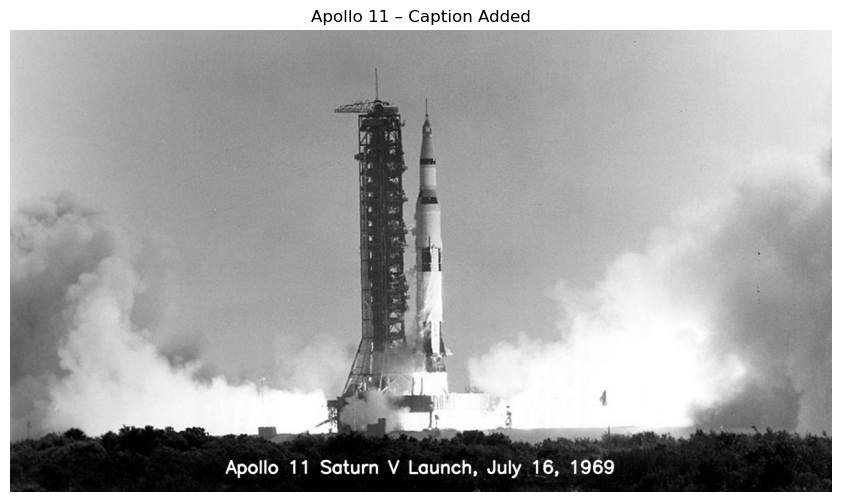

In [19]:
apollo_annotated = apollo_bgr.copy()
caption = "Apollo 11 Saturn V Launch, July 16, 1969"
h, w = apollo_annotated.shape[:2]
font = cv2.FONT_HERSHEY_SIMPLEX
scale = min(0.9, w / 1100)
thickness = 2
(text_w, text_h), baseline = cv2.getTextSize(caption, font, scale, thickness)
x = max(0, (w - text_w) // 2)
y = h - 30
cv2.putText(apollo_annotated, caption, (x, y), font, scale, (255, 255, 255), thickness, cv2.LINE_AA)
plt.figure(figsize=(11, 6))
plt.imshow(cv2.cvtColor(apollo_annotated, cv2.COLOR_BGR2RGB))
plt.title("Apollo 11 – Caption Added")
plt.axis("off")
plt.show()

In [20]:
# Approximate bounds for the supplied 1280 × 720 image.
# OpenCV drawing uses BGR: magenta = (255, 0, 255).
cv2.rectangle(apollo_annotated, (480, 55), (705, 630), (255, 0, 255), 4)
print("Magenta rectangle drawn")

Magenta rectangle drawn


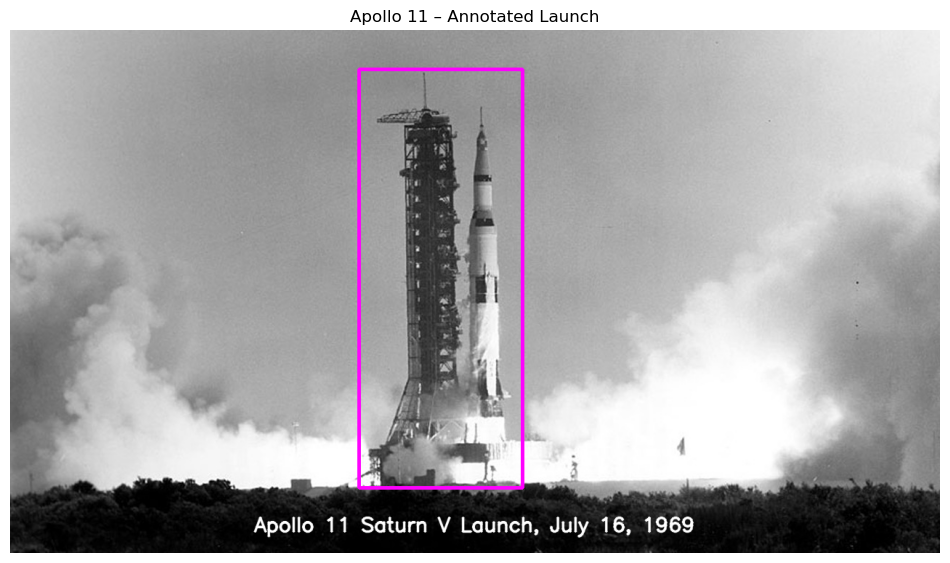

True

In [21]:
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(apollo_annotated, cv2.COLOR_BGR2RGB))
plt.title("Apollo 11 – Annotated Launch")
plt.axis("off")
plt.show()
cv2.imwrite("apollo_annotated.png", apollo_annotated)

Boy image shape: (360, 480, 3)


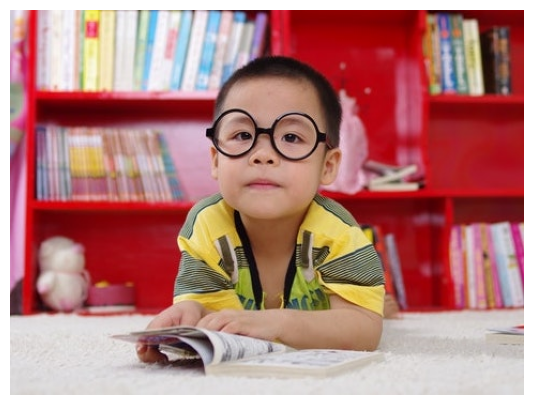

In [23]:
boy_bgr = cv2.imread("boy.jpeg", cv2.IMREAD_COLOR)
assert boy_bgr is not None
boy_rgb = cv2.cvtColor(boy_bgr, cv2.COLOR_BGR2RGB)
print("Boy image shape:", boy_rgb.shape)
plt.figure(figsize=(8, 5))
plt.imshow(boy_rgb)
plt.axis("off")
plt.show()

In [24]:
brightness_matrix = np.full(boy_rgb.shape, 50, dtype=np.uint8)
print("Brightness change:", brightness_matrix[0, 0])

Brightness change: [50 50 50]


In [25]:
boy_brighter = cv2.add(boy_rgb, brightness_matrix)
boy_darker = cv2.subtract(boy_rgb, brightness_matrix)

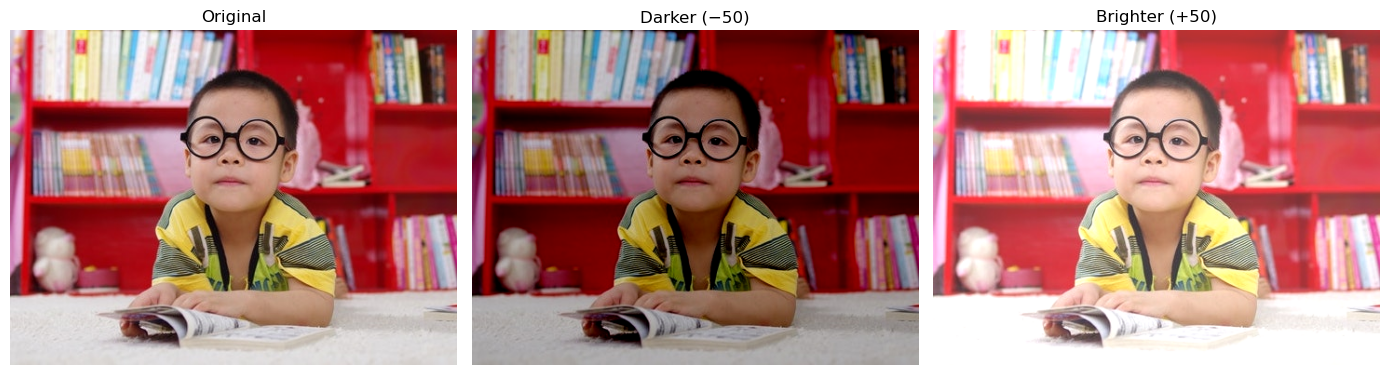

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, im, title in zip(ax, [boy_rgb, boy_darker, boy_brighter], ["Original", "Darker (−50)", "Brighter (+50)"]):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

In [27]:
# Alpha > 1 increases contrast; alpha < 1 reduces contrast.
# Beta shifts brightness so the scaling is around mid-gray (128).
def adjust_contrast(image, alpha):
    return np.clip((image.astype(np.float32) - 128) * alpha + 128, 0, 255).astype(np.uint8)

boy_lower_contrast = adjust_contrast(boy_rgb, 0.8)
boy_higher_contrast = adjust_contrast(boy_rgb, 1.2)
# Additional 1.1× result, as mentioned in the supplied exercise:
boy_contrast_1_1 = adjust_contrast(boy_rgb, 1.1)

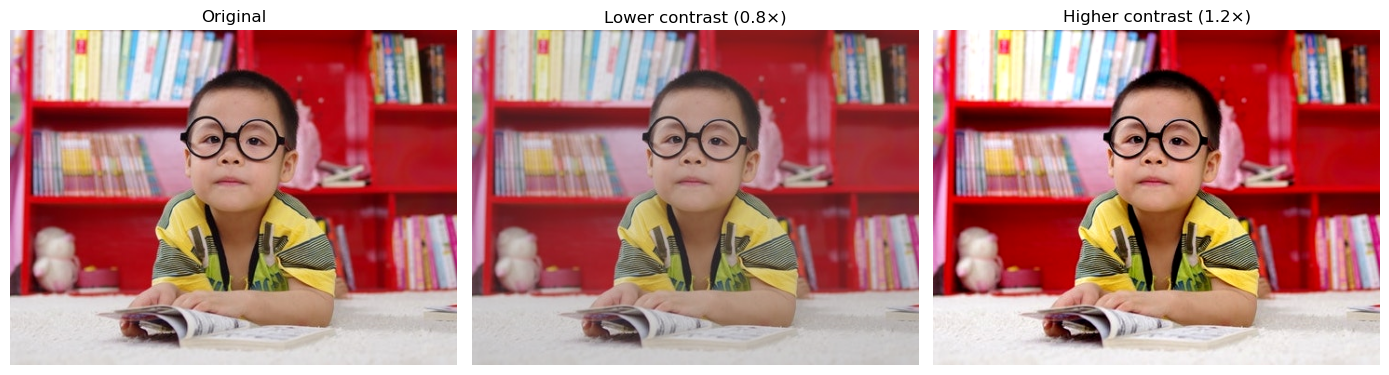

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, im, title in zip(ax, [boy_rgb, boy_lower_contrast, boy_higher_contrast], ["Original", "Lower contrast (0.8×)", "Higher contrast (1.2×)"]):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

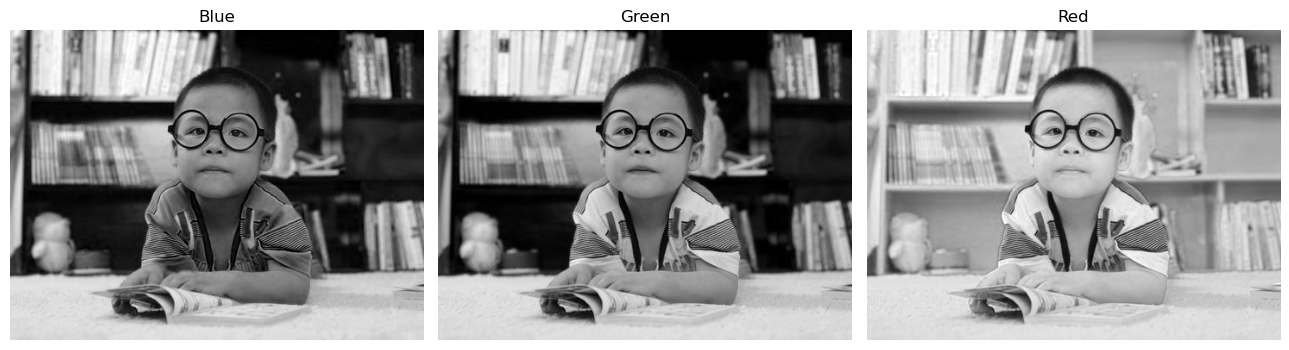

In [29]:
b, g, r = cv2.split(boy_bgr)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, channel, title in zip(ax, [b, g, r], ["Blue", "Green", "Red"]):
    a.imshow(channel, cmap="gray", vmin=0, vmax=255); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

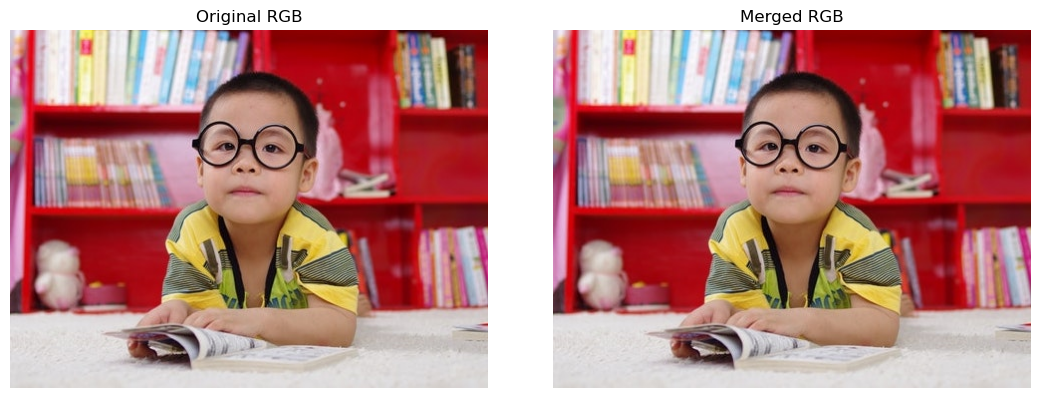

Identical: True


In [30]:
merged_rgb = cv2.merge([r, g, b])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, im, title in zip(ax, [boy_rgb, merged_rgb], ["Original RGB", "Merged RGB"]):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()
print("Identical:", np.array_equal(boy_rgb, merged_rgb))

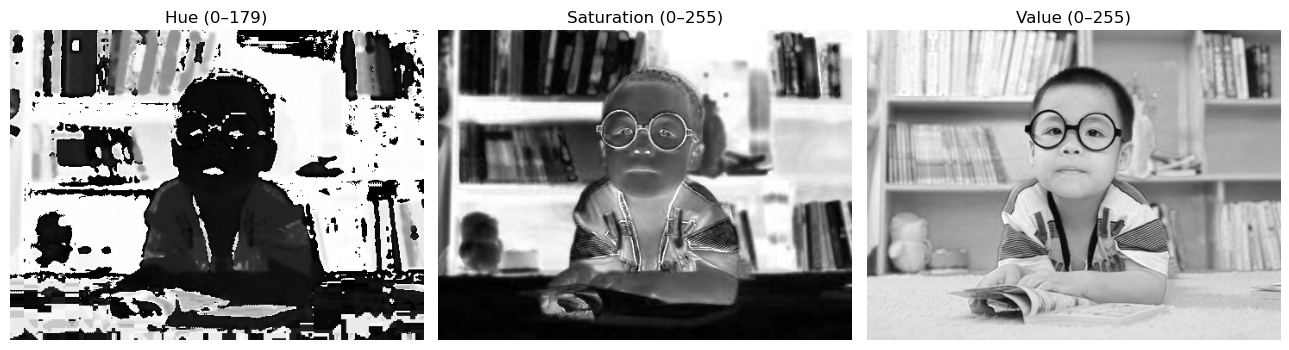

In [31]:
hsv_img = cv2.cvtColor(boy_bgr, cv2.COLOR_BGR2HSV)
hue, saturation, value = cv2.split(hsv_img)
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, ch, title in zip(ax, [hue, saturation, value], ["Hue (0–179)", "Saturation (0–255)", "Value (0–255)"]):
    a.imshow(ch, cmap="gray"); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

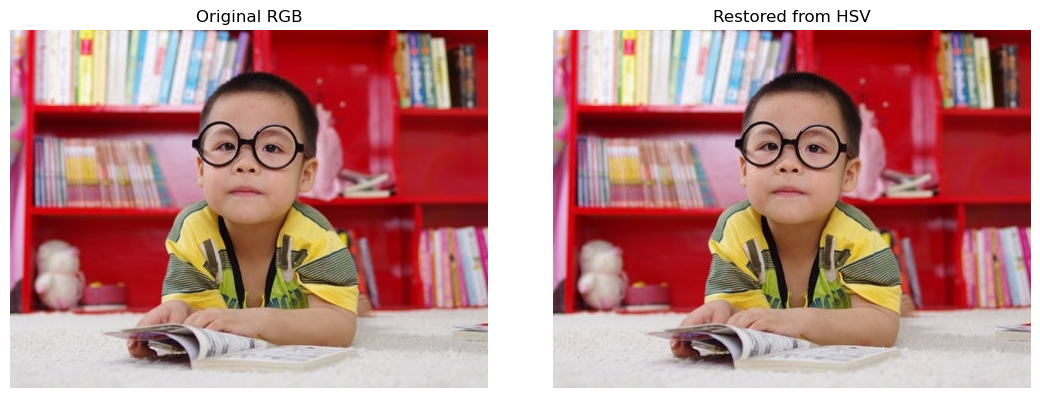

Max rounding difference: 4


In [32]:
merged_hsv = cv2.merge([hue, saturation, value])
restored_bgr = cv2.cvtColor(merged_hsv, cv2.COLOR_HSV2BGR)
restored_rgb = cv2.cvtColor(restored_bgr, cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, im, title in zip(ax, [boy_rgb, restored_rgb], ["Original RGB", "Restored from HSV"]):
    a.imshow(im); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()
print("Max rounding difference:", np.abs(boy_rgb.astype(int) - restored_rgb.astype(int)).max())